# Food Delivery Operations — Complete Data Analytics Project
**Kagnus | End-to-end analysis | Python, Pandas, NumPy, Matplotlib, Seaborn**

**Objective:** Inspect the approved dataset, document cleaning decisions, explore delivery duration across available operational fields, create evidence-backed charts, and recommend practical actions. This notebook combines all four project stages in one executable deliverable. Observational associations do **not** establish causation.

**Dataset:** Kagnus Food Delivery Dataset (source URL in the repository README). One row represents one delivery record identified by `ID`. The target is `Time_taken (min)`; its precise start/end definition is not supplied. No machine learning is required.

## 1. Setup and load data
We load the provided cleaned file created during the documented quality-control stage. The raw CSV is deliberately not included in the distributable repository until redistribution rights are confirmed. To reproduce the cleaning stage from raw data, consult the separate `01_data_understanding_and_cleaning.ipynb` and download the original from Kagnus.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "cleaned_food_delivery.csv").exists():
    ROOT = ROOT.parent
path = ROOT / "data" / "processed" / "cleaned_food_delivery.csv"
df = pd.read_csv(path)
print("Dataset shape:", df.shape)
display(df.head(), df.tail())
print("Columns:", df.columns.tolist())
df.info()
display(df.describe(include="all").T)

Dataset shape: (45584, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
45579,0x7c09,JAPRES04DEL01,30.0,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35,11:45,Windy,High,1,Meal,motorcycle,0.0,No,Metropolitian,32
45580,0xd641,AGRRES16DEL01,21.0,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55,20:10,Windy,Jam,0,Buffet,motorcycle,1.0,No,Metropolitian,36
45581,0x4f8d,CHENRES08DEL03,30.0,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50,24:05:00,Cloudy,Low,1,Drinks,scooter,0.0,No,Metropolitian,16
45582,0x5eee,COIMBRES11DEL01,20.0,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35,13:40,Cloudy,High,0,Snack,motorcycle,1.0,No,Metropolitian,26
45583,0x5fb2,RANCHIRES09DEL02,23.0,4.9,23.351058,85.325731,23.431058,85.405731,02-03-2022,17:10,17:15,Fog,Medium,2,Snack,scooter,1.0,No,Metropolitian,36


Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_l

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,45584,45584,0xcdcd,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_ID,45584,1320,JAPRES11DEL02,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_Age,43730.0,NaN,NaN,NaN,29.566911,5.815064,15.0,25.0,30.0,35.0,50.0
Delivery_person_Ratings,43676.0,NaN,NaN,NaN,4.633774,0.334744,1.0,4.5,4.7,4.9,6.0
Restaurant_latitude,45584.0,NaN,NaN,NaN,17.017948,8.185674,-30.905562,12.933284,18.55144,22.728163,30.914057
Restaurant_longitude,45584.0,NaN,NaN,NaN,70.229684,22.885575,-88.366217,73.17,75.897963,78.044095,88.433452
Delivery_location_latitude,45584.0,NaN,NaN,NaN,17.46548,7.335562,0.01,12.988453,18.633934,22.785049,31.054057
Delivery_location_longitude,45584.0,NaN,NaN,NaN,70.844161,21.120578,0.01,73.28,76.002574,78.107044,88.563452
Order_Date,45584,44,15-03-2022,1192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_Orderd,43853,176,21:55,461,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Column dictionary
The column descriptions below follow the labels supplied in the dataset. Some fields (notably the exact definition of delivery duration and vehicle condition coding) lack a formal data dictionary; these are treated as limitations.

In [2]:
descriptions = {
"ID":"Delivery record identifier", "Delivery_person_ID":"Delivery partner identifier", "Delivery_person_Age":"Partner age (years)", "Delivery_person_Ratings":"Partner rating (scale not explicitly documented)",
"Restaurant_latitude":"Restaurant latitude (degrees)","Restaurant_longitude":"Restaurant longitude (degrees)","Delivery_location_latitude":"Drop-off latitude (degrees)","Delivery_location_longitude":"Drop-off longitude (degrees)",
"Order_Date":"Recorded order date", "Time_Orderd":"Recorded order time", "Time_Order_picked":"Recorded pickup time", "Weather_conditions":"Weather category", "Road_traffic_density":"Traffic category", "Vehicle_condition":"Coded vehicle condition (coding undocumented)", "Type_of_order":"Food order category", "Type_of_vehicle":"Delivery vehicle category", "multiple_deliveries":"Recorded number/code for multiple deliveries (definition unverified)", "Festival":"Festival indicator", "City":"City classification", "Time_taken (min)":"Recorded delivery duration in minutes (timing boundaries unspecified)"}
column_overview = pd.DataFrame({"column":df.columns,"dtype":[str(df[c].dtype) for c in df.columns],"meaning":[descriptions.get(c,"Not documented") for c in df.columns]})
display(column_overview)

,column,dtype,meaning
0,ID,object,Delivery record identifier
1,Delivery_person_ID,object,Delivery partner identifier
2,Delivery_person_Age,float64,Partner age (years)
3,Delivery_person_Ratings,float64,Partner rating (scale not explicitly documented)
4,Restaurant_latitude,float64,Restaurant latitude (degrees)
5,Restaurant_longitude,float64,Restaurant longitude (degrees)
6,Delivery_location_latitude,float64,Drop-off latitude (degrees)
7,Delivery_location_longitude,float64,Drop-off longitude (degrees)
8,Order_Date,object,Recorded order date
9,Time_Orderd,object,Recorded order time


## 2. Quality assessment and cleaning decisions
The dedicated cleaning notebook performs the raw-data checks and exports the cleaned file. Here we verify remaining missing values and the documented log. We do not drop missing or unusual observations simply to improve plots.

In [3]:
quality = pd.DataFrame({"missing_count":df.isna().sum(),"missing_percent":(df.isna().mean()*100).round(2),"dtype":df.dtypes.astype(str)})
display(quality)
print("Exact duplicates:",df.duplicated().sum(),"Duplicate IDs:",df['ID'].duplicated().sum())
log=pd.read_csv(ROOT/'docs'/'cleaning_log.csv');display(log)
print("Cleaned row count:",len(df))

,missing_count,missing_percent,dtype
ID,0,0.00,object
Delivery_person_ID,0,0.00,object
Delivery_person_Age,1854,4.07,float64
Delivery_person_Ratings,1908,4.19,float64
Restaurant_latitude,0,0.00,float64
Restaurant_longitude,0,0.00,float64
Delivery_location_latitude,0,0.00,float64
Delivery_location_longitude,0,0.00,float64
Order_Date,0,0.00,object
Time_Orderd,1731,3.80,object


Exact duplicates: 0 Duplicate IDs: 0


,issue,affected_column,affected_rows,action_taken,reason
0,Whitespace/case label consistency,Weather_conditions,0,Checked; no changes,Only equivalent labels were standardized; no u...
1,Whitespace/case label consistency,Road_traffic_density,0,Checked; no changes,Only equivalent labels were standardized; no u...
2,Whitespace/case label consistency,Type_of_order,0,Checked; no changes,Only equivalent labels were standardized; no u...
3,Whitespace/case label consistency,Type_of_vehicle,0,Checked; no changes,Only equivalent labels were standardized; no u...
4,Whitespace/case label consistency,Festival,0,Checked; no changes,Only equivalent labels were standardized; no u...
5,Whitespace/case label consistency,City,0,Checked; no changes,Only equivalent labels were standardized; no u...
6,Missing values,Delivery_person_Age,1854,Retained as missing,No validated source or defensible imputation r...
7,Missing values,Delivery_person_Ratings,1908,Retained as missing,No validated source or defensible imputation r...
8,Missing values,Time_Orderd,1731,Retained as missing,No validated source or defensible imputation r...
9,Missing values,Weather_conditions,616,Retained as missing,No validated source or defensible imputation r...


Cleaned row count: 45584


## 3. Analysis preparation
We trim category whitespace for reliable group comparisons. A misspelled city class is standardized **for analysis only**. Distance is an approximate great-circle distance, not road distance. Coordinates with invalid or non-positive values, or distances above 100 km, are excluded **only from distance analysis**; all records remain available for other summaries. The 100 km cutoff is a conservative analytic filter, not a claim that such trips are impossible.

In [4]:
for c in ['Weather_conditions','Road_traffic_density','Type_of_order','Type_of_vehicle','Festival','City']:
    df[c] = df[c].astype('string').str.strip().replace({'Metropolitian':'Metropolitan'})
valid = (df['Restaurant_latitude'].between(-90,90)&df['Delivery_location_latitude'].between(-90,90)&df['Restaurant_longitude'].between(-180,180)&df['Delivery_location_longitude'].between(-180,180)&(df['Restaurant_latitude']>0)&(df['Delivery_location_latitude']>0)&(df['Restaurant_longitude']>0)&(df['Delivery_location_longitude']>0))
lat1=np.radians(df.loc[valid,'Restaurant_latitude'].to_numpy());lat2=np.radians(df.loc[valid,'Delivery_location_latitude'].to_numpy())
dlat=lat2-lat1;dlon=np.radians(df.loc[valid,'Delivery_location_longitude'].to_numpy()-df.loc[valid,'Restaurant_longitude'].to_numpy())
a=np.sin(dlat/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
df['straight_line_km']=np.nan
df.loc[valid,'straight_line_km']=6371*2*np.arcsin(np.minimum(1,np.sqrt(a)))
df.loc[df['straight_line_km']>100,'straight_line_km']=np.nan
print('Rows usable for distance:',df['straight_line_km'].notna().sum())
print('Rows excluded from distance calculation:',df['straight_line_km'].isna().sum())

Rows usable for distance: 41513
Rows excluded from distance calculation: 4071


## 4. Exploratory analysis
For each operational factor, we report the number of non-missing duration observations, mean duration, and median duration. Counts matter: small or missing groups should not be over-interpreted.

In [5]:
metric='Time_taken (min)'
fields={'traffic':'Road_traffic_density','weather':'Weather_conditions','vehicle':'Type_of_vehicle','city':'City','order':'Type_of_order','festival':'Festival','multiple deliveries':'multiple_deliveries'}
summaries={}
for name,col in fields.items():
    summary=df.groupby(col,dropna=False)[metric].agg(['count','mean','median']).round(2).sort_values('mean',ascending=False)
    summaries[name]=summary
    print('\n'+name.upper());display(summary)
print('Overall average (minutes):',round(df[metric].mean(),2))
print('Overall median (minutes):',round(df[metric].median(),2))


TRAFFIC


,count,mean,median
Road_traffic_density,,,
Jam,14139,31.18,31.0
High,4423,27.24,27.0
Medium,10945,26.70,27.0
<NA>,601,26.54,26.0
Low,15476,21.27,20.0



WEATHER


,count,mean,median
Weather_conditions,,,
Cloudy,7533,28.92,28.0
Fog,7653,28.91,28.0
<NA>,616,26.55,26.0
Windy,7422,26.12,26.0
Sandstorms,7494,25.88,26.0
Stormy,7584,25.87,26.0
Sunny,7282,21.86,20.0



VEHICLE


,count,mean,median
Type_of_vehicle,,,
motorcycle,26429,27.61,26.0
bicycle,68,26.43,26.0
scooter,15273,24.48,24.0
electric_scooter,3814,24.47,24.0


... (5 outputs left out)

,count,mean,median
Festival,,,
Yes,896,45.52,45.0
No,44460,25.98,25.0
<NA>,228,11.17,11.0



MULTIPLE DELIVERIES


,count,mean,median
multiple_deliveries,,,
3.0,361,47.82,48.0
2.0,1985,40.45,40.0
1.0,28151,26.85,26.0
0.0,14094,22.88,22.0
NaN,993,22.77,21.0


Overall average (minutes): 26.29
Overall median (minutes): 26.0


## 5. Visualizations
These six charts display group-level associations. The bars use means in minutes, and the source tables above provide group sizes. Differences may reflect confounding factors; none prove that an individual variable causes delays.

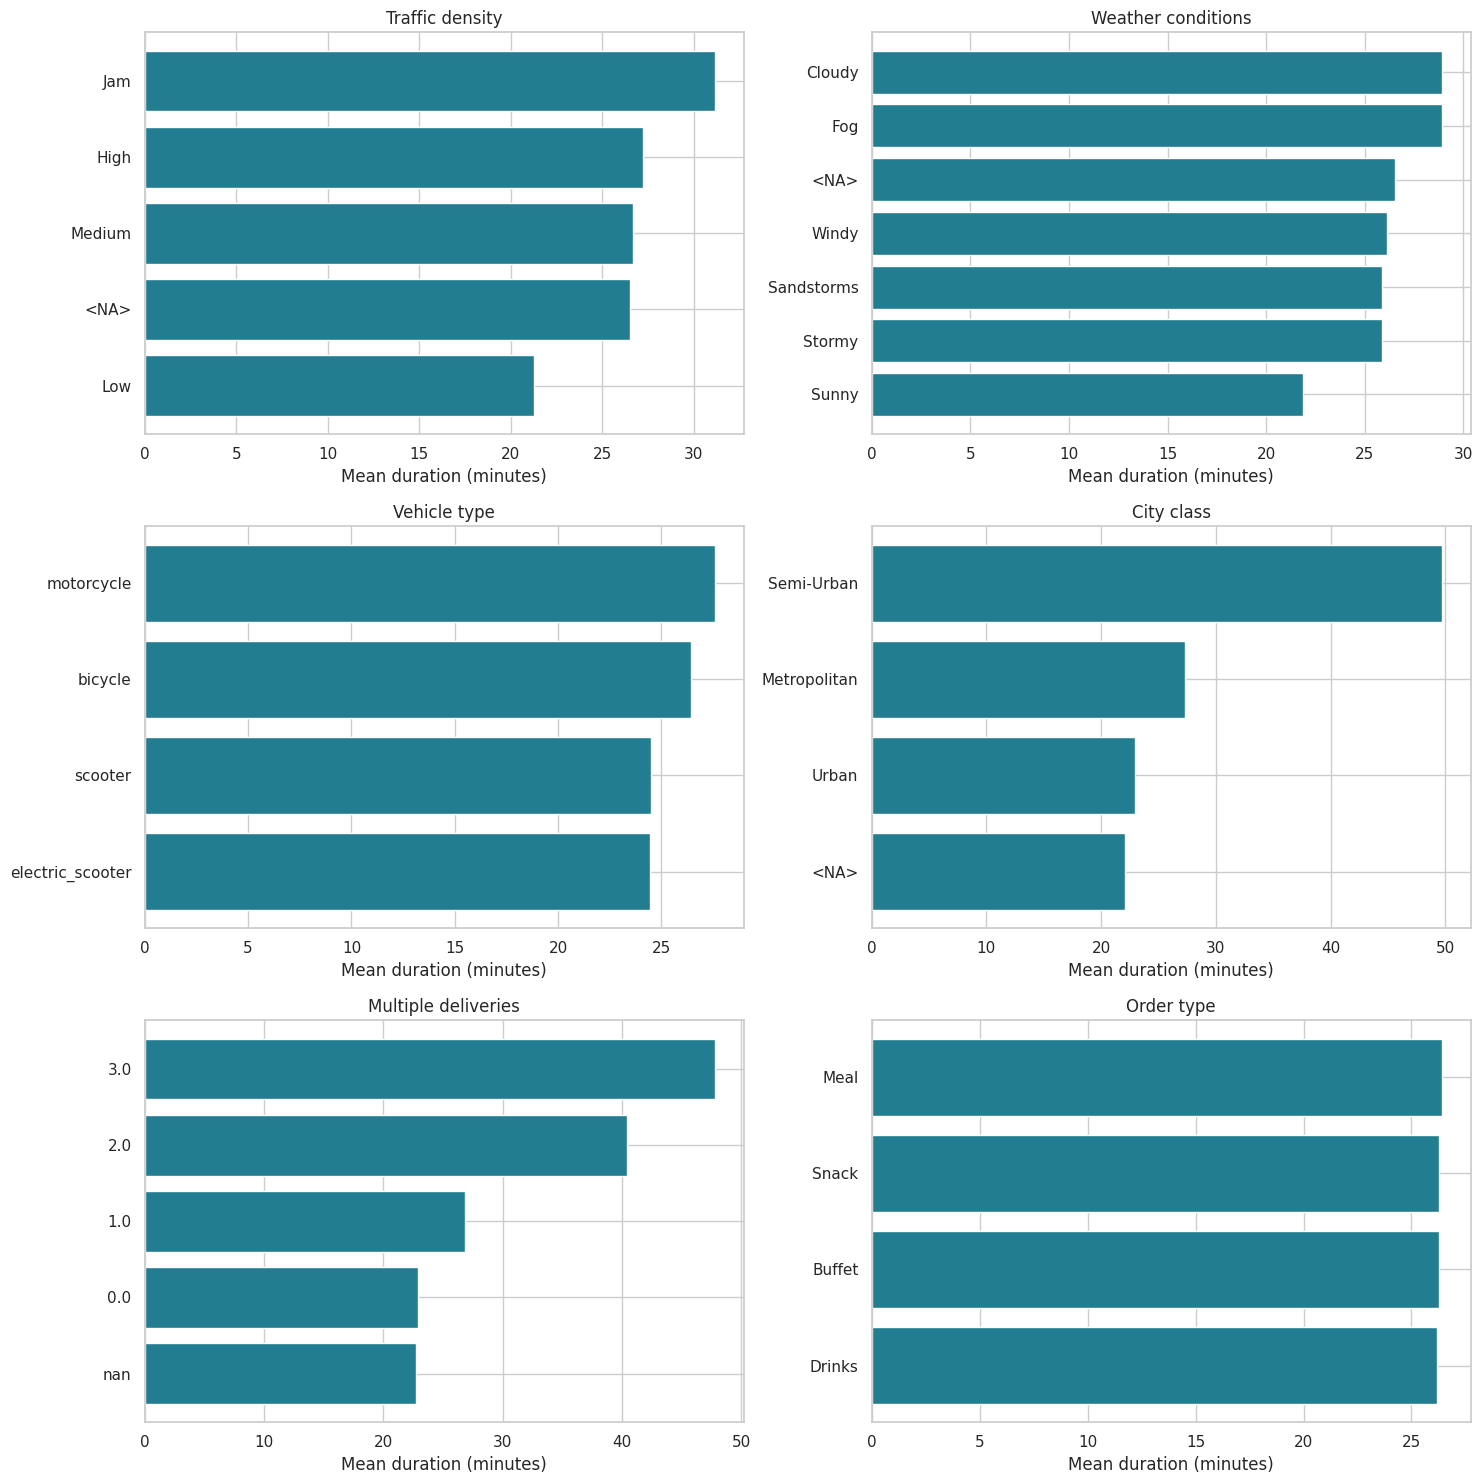

In [6]:
fig,axes=plt.subplots(3,2,figsize=(15,15))
plot_items=[('traffic','Traffic density'),('weather','Weather conditions'),('vehicle','Vehicle type'),('city','City class'),('multiple deliveries','Multiple deliveries'),('order','Order type')]
for ax,(key,title) in zip(axes.flat,plot_items):
    table=summaries[key].dropna(subset=['mean']).sort_values('mean')
    ax.barh([str(v) for v in table.index],table['mean'],color='#237d91')
    ax.set_title(title);ax.set_xlabel('Mean duration (minutes)')
plt.tight_layout();plt.show()

### Distance analysis
Distance is straight-line (haversine), so it underestimates actual road travel. Invalid coordinates and extreme calculated distances are omitted only from this particular comparison.

,count,mean,median
distance_band,,,
"(-0.001, 2.0]",3746,21.46,20.0
"(2.0, 5.0]",7438,22.55,22.0
"(5.0, 10.0]",11185,24.39,25.0
"(10.0, 20.0]",17367,29.86,29.0
"(20.0, 100.0]",1777,29.78,29.0


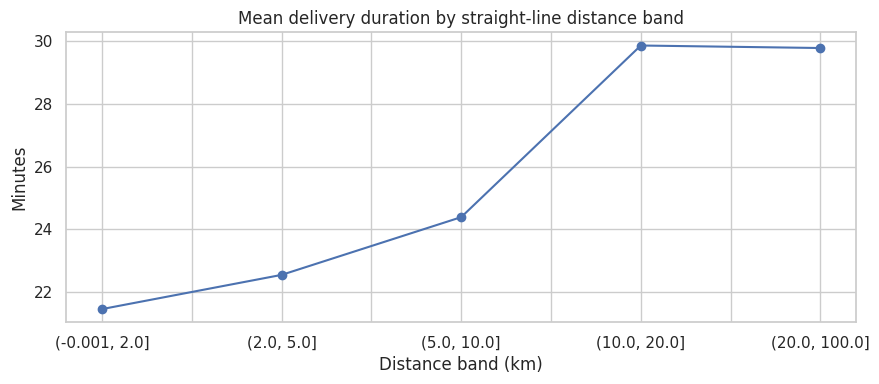

In [7]:
distance_data=df.dropna(subset=['straight_line_km']).copy()
distance_data['distance_band']=pd.cut(distance_data['straight_line_km'],bins=[0,2,5,10,20,100],include_lowest=True)
distance_summary=distance_data.groupby('distance_band',observed=True)[metric].agg(['count','mean','median']).round(2)
display(distance_summary)
if len(distance_summary):
    distance_summary['mean'].plot(marker='o',figsize=(9,4),title='Mean delivery duration by straight-line distance band')
    plt.ylabel('Minutes');plt.xlabel('Distance band (km)');plt.tight_layout();plt.show()

## 6. Evidence-backed findings
The following observations are **generated from the actual computed tables**, not manually assumed. A gap describes an association between groups, not a causal effect.

In [8]:
findings=[]
for key,label in [('traffic','Traffic density'),('weather','Weather'),('vehicle','Vehicle type'),('city','City classification'),('multiple deliveries','Multiple deliveries'),('order','Order type')]:
    table=summaries[key].dropna(subset=['mean'])
    table=table.loc[~table.index.isna()]
    if len(table)>=2:
        high=table['mean'].idxmax();low=table['mean'].idxmin();gap=table.loc[high,'mean']-table.loc[low,'mean']
        findings.append(f'{label}: {high} averaged {table.loc[high,"mean"]:.2f} min (n={int(table.loc[high,"count"]):,}) versus {low} at {table.loc[low,"mean"]:.2f} min (n={int(table.loc[low,"count"]):,}); observed gap {gap:.2f} min.')
for i,s in enumerate(findings,1):print(f'{i}. {s}')

1. Traffic density: Jam averaged 31.18 min (n=14,139) versus Low at 21.27 min (n=15,476); observed gap 9.91 min.
2. Weather: Cloudy averaged 28.92 min (n=7,533) versus Sunny at 21.86 min (n=7,282); observed gap 7.06 min.
3. Vehicle type: motorcycle averaged 27.61 min (n=26,429) versus electric_scooter at 24.47 min (n=3,814); observed gap 3.14 min.
4. City classification: Semi-Urban averaged 49.73 min (n=164) versus Urban at 22.98 min (n=10,133); observed gap 26.75 min.
5. Multiple deliveries: 3.0 averaged 47.82 min (n=361) versus 0.0 at 22.88 min (n=14,094); observed gap 24.94 min.
6. Order type: Meal averaged 26.42 min (n=11,456) versus Drinks at 26.19 min (n=11,321); observed gap 0.23 min.


## 7. Operational recommendations and limitations
**Recommendations:** (1) Monitor the higher-duration traffic and weather categories when allocating delivery capacity; (2) compare vehicle and city patterns within similar distance/traffic bands before making staffing decisions; (3) track missing partner and location attributes to improve operational reporting; (4) validate unusual coordinates and rating values with the data owner; (5) test any proposed routing or staffing changes experimentally rather than treating these associations as causal.

**Limitations:** Missing values are retained; distance is straight-line rather than route distance; category samples vary; some location coordinates may be inaccurate; the dataset does not define every coding convention or exact delivery-duration boundaries; there is no causal adjustment for simultaneous factors. Findings describe this historical dataset, not live performance.

## 8. Final reproducibility checks
Verify row count, unique IDs, and exported dataset readability. The raw and processed CSVs are separate. Project-level charts and a PDF report are also supplied in the repository.

In [9]:
reloaded=pd.read_csv(ROOT/'data'/'processed'/'cleaned_food_delivery.csv')
assert len(reloaded)==len(df)
assert reloaded['ID'].is_unique
print('PASS: cleaned CSV reopened; rows:',len(reloaded),'columns:',len(reloaded.columns))
print('Charts in:',ROOT/'charts')
print('Final report:',ROOT/'reports'/'Food_Delivery_Analysis_Final_Report.pdf')

PASS: cleaned CSV reopened; rows: 45584 columns: 20
Charts in: /mnt/data/food-delivery-complete-project/charts
Final report: /mnt/data/food-delivery-complete-project/reports/Food_Delivery_Analysis_Final_Report.pdf
